# Figure S13B — disorder across viral lineages (total fraction across proteome)

Each point is one viral proteome; its value is the total fraction of residues predicted disordered across the whole proteome (TFAP). Lineages (the first rank below "Viruses" in the UniProt lineage) with at least 10 proteomes are shown, ordered by mean disorder; black bars mark the mean. Single-gene proteomes and the non-taxonomic "unclassified …" / "environmental samples" bins are excluded. This is the TFAP counterpart of Figure 3B (which uses the average fraction per protein).

**How it is made.** Reads the per-proteome disorder table and UniProt lineages in `data/viral_proteomes/` in the shared data directory. **These disorder values come from the 2024 metapredict V3 prediction of 23,129 UniProt reference proteomes and predate metapredict 3.1.0**; they are not regenerated here.

**Correction vs the published panel.** The original notebook set the metric to TFAP but never passed it to the grouping function, which defaulted to the per-protein average (AFPP), so the published S6B duplicated Figure 3B (Figure 2B in the published version). Here the TFAP values are actually used.

**Output:** `figures/figure_S13B.pdf` (drawn vertically; rotated 90° in the assembled figure)

In [1]:
import random

import numpy as np

from figtools import apply_style, save_panel, shared_data_path
from viral_disorder import (break_down_into_groups, graph_lineages, load_lineages,
                            load_single_gene_viruses, load_viral_disorder)

apply_style()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

# seed for the random horizontal jitter of points
JITTER_SEED = 2024
random.seed(JITTER_SEED)
np.random.seed(JITTER_SEED)

# lineages with fewer proteomes than this are not shown
MIN_PER_GROUP = 10
# TFAP: disordered residues / all residues, per proteome
DISORDER_VALS = 'total_proteome'

In [2]:
single_gene_virus = load_single_gene_viruses(str(shared_data_path('viral_proteomes', 'viral_proteome_id_to_count.tsv')))
viruses = load_lineages(str(shared_data_path('viral_proteomes', 'viruses_w_lineage.tsv')))
vir_dis_dict = load_viral_disorder(str(shared_data_path('viral_proteomes',
                                                  'viral_proteome_fraction_disorder_by_prot_and_total_proteome.tsv')),
                                   exclude=single_gene_virus)
print(f'{len(single_gene_virus)} single-gene proteomes excluded; {len(vir_dis_dict)} proteomes kept')

# top-level viral group = first lineage rank after 'Viruses'
viral_groups = set()
for lineage in viruses.values():
    ranks = lineage.split(',')
    if ranks[0] == 'Viruses':
        viral_groups.add(ranks[1][1:])

# 'unclassified ...' and 'environmental samples' are not taxa; the published panel
# omitted them (removed at assembly in the original), here they are dropped in code
non_taxonomic = sorted(g for g in viral_groups if g.startswith('unclassified') or g == 'environmental samples')
viral_groups = [g for g in viral_groups if g not in non_taxonomic]
print(f'non-taxonomic groups excluded: {non_taxonomic}')

814 single-gene proteomes excluded; 10014 proteomes kept
non-taxonomic groups excluded: ['environmental samples', 'unclassified archaeal viruses', 'unclassified bacterial viruses', 'unclassified viruses']


In [3]:
# keep groups with enough proteomes, then order them by mean disorder (low -> high)
graph_groups = break_down_into_groups(viral_groups, viruses, vir_dis_dict, min_per_group=MIN_PER_GROUP,
                                      vals=DISORDER_VALS)
mean_by_group = {group: np.mean(values) for group, values in graph_groups.items()}
final_groups = sorted(mean_by_group, key=mean_by_group.get)
graph_values = break_down_into_groups(final_groups, viruses, vir_dis_dict, min_per_group=MIN_PER_GROUP,
                                      vals=DISORDER_VALS)
# per-protein (AFPP) means for comparison with Figure 3B / the published S6B
afpp = break_down_into_groups(final_groups, viruses, vir_dis_dict, min_per_group=MIN_PER_GROUP,
                              vals='per_protein')
for group in graph_values:
    print(f'{group:20s} n = {len(graph_values[group]):5d}  TFAP mean = {mean_by_group[group]:.3f}  '
          f'(AFPP mean = {np.mean(afpp[group]):.3f})')

Adnaviria            n =    18  TFAP mean = 0.047  (AFPP mean = 0.069)
Fuselloviridae       n =    13  TFAP mean = 0.093  (AFPP mean = 0.134)
Duplodnaviria        n =  4458  TFAP mean = 0.110  (AFPP mean = 0.143)
Riboviria            n =  3041  TFAP mean = 0.115  (AFPP mean = 0.157)
Naldaviricetes       n =    81  TFAP mean = 0.155  (AFPP mean = 0.190)
Alphasatellitidae    n =    11  TFAP mean = 0.186  (AFPP mean = 0.240)
Varidnaviria         n =   235  TFAP mean = 0.189  (AFPP mean = 0.247)
Monodnaviria         n =  1467  TFAP mean = 0.232  (AFPP mean = 0.276)
Anelloviridae        n =   115  TFAP mean = 0.510  (AFPP mean = 0.626)


Wrote figures/figure_S13B.pdf


PosixPath('figures/figure_S13B.pdf')

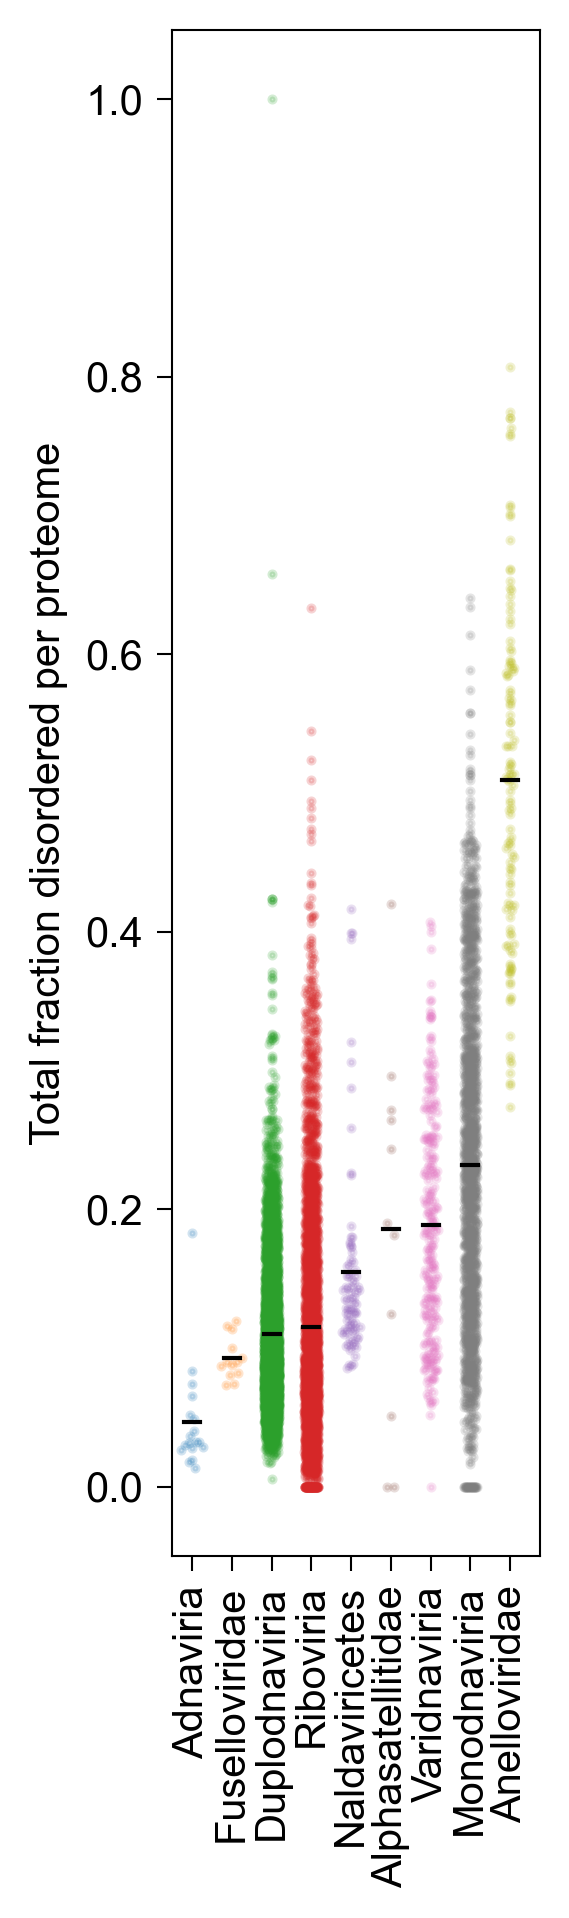

In [4]:
fig = graph_lineages(graph_values, ylabel='Total fraction disordered per proteome', figsize=(2, 6.5),
                     s=8, alpha=0.2)
save_panel(fig, 'figure_S13B')